## **Introduction:**




Explainable AI, also known as interpretable AI, refers to the ability of an artificial intelligence model to provide understandable explanations for its decisions or predictions. This transparency is particularly crucial for industries such as financial institutions and healthcare companies due to the following reasons:

1- Regulatory Compliance: Both financial institutions and healthcare companies operate within heavily regulated environments. They are bound by laws and regulations that require transparency, fairness, and accountability in decision-making. Explainable AI helps meet these regulatory requirements by providing clear explanations for the factors that influenced a particular decision, thus ensuring compliance.

2- Trust and Risk Assessment: Financial institutions and healthcare companies handle sensitive and critical information, including financial transactions, patient records, and medical diagnoses. By using explainable AI models, these organizations can enhance transparency and build trust with their customers, clients, and patients. When individuals understand the reasoning behind an AI-driven decision, they are more likely to trust and accept its outcomes.

3- Bias Detection and Mitigation: AI models trained on historical data can unintentionally learn biases present in the data, which can lead to biased decisions. In finance and healthcare, biased decisions can have significant consequences. Explainable AI allows organizations to identify and address biases by providing insights into the model's decision-making process, making it easier to detect and mitigate any unfair or discriminatory practices.

4- Model Validation and Auditing: Financial institutions and healthcare companies need to ensure that their AI models are accurate, reliable, and fair. Explainable AI enables model validation and auditing by allowing experts to understand how the model arrives at its predictions or decisions. It helps identify potential flaws or biases in the model's design or training data, enabling organizations to make necessary improvements.

5- Error Diagnosis and Resolution: In complex domains such as finance and healthcare, AI models can make mistakes or provide incorrect predictions. Explainable AI facilitates error diagnosis by providing insights into the factors that influenced a particular decision. This information can aid experts in identifying the cause of errors and devising solutions to improve model performance and reliability.

6- Human-AI Collaboration: Financial institutions and healthcare companies often involve human experts in decision-making processes. Explainable AI facilitates collaboration between humans and AI systems by providing interpretable explanations that humans can understand and validate. It allows experts to combine their domain knowledge with AI-generated insights, leading to more informed and effective decision-making.





---

## **Data Overview**


****
Data
****
| Column Name          | Data Type                | Description                   |
|----------------------|--------------------------|-------------------------------|
| User id              | Integer                  | Unique user identifier        |
| Loan category        | String                   | Categorical variable          |
| Amount               | Integer                  | Loan amount                   |
| Interest Rate        | Integer                  | Interest rate                 |
| Tenure               | Integer                  | Loan tenure                   |
| Employment type      | String                   | Categorical variable          |
| Tier of Employment   | Categorical and Ordinal  | Employment tier classification|
| Industry             | Categorical              | Industry type                 |
| Role                 | Categorical              | Role description              |
| Work Experience      | Categorical and Ordinal  | Work experience category      |
| Total Income(PA)     | Integer                  | Total annual income           |
| Gender               | Categorical              | Gender of the user            |
| Married              | Categorical              | Marital status                |
| Dependents           | Integer                  | Number of dependents          |
| Home                 | Categorical              | Housing category              |
| Pincode              | Unknown                  | Pincode information           |
| Social Profile       | Categorical              | Social profile of the user    |
| Is_verified          | Categorical              | Verification status           |
| Delinq_2yrs          | Integer                  | Number of delinquencies       |
| Total Payment        | Integer                  | Total payment received        |
| Received Principal   | Integer                  | Principal amount received     |
| Interest Received    | Integer                  | Interest amount received      |
| Number of loans      | Integer                  | Number of loans taken          |
| Defaulter            | Categorical              | Loan defaulter classification |

****
**Column to be predicted "Defaulter"**

## **Importing Packages**

In [1]:
!pip install -U graphviz scikit-learn neptune-xgboost xgboost hyperopt mlflow deepchecks
!pip install -U "neptune[xgboost]"

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 200.3/200.3 MB 5.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.1/18.1 MB 82.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 115.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 83.5/83.5 kB 9.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 184.3/184.3 kB 19.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 224.5/224.5 kB 23.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.1/148.1 kB 16.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 8.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 81.9/81.9 kB 10.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.7/78.7 kB 10.3 MB/s eta 0:00:00
     ━━━━━━━

In [40]:
import pandas as pd
import numpy as np
import os
import pandas as pd
import warnings
warnings.filterwarnings('ignore')


In [14]:
from Source.setup import *
from Source.eda import *
from Source.machine_learning import *

## **Reading and Merging Data**



In [15]:
# Specify the file path of the Excel file containing the dataset
path = '../Input/Credit_Risk_Dataset.xlsx'

# Call the function to read the Excel data
sheet_names= ['loan_information', 'Employment','Personal_information', 'Other_information' ]

dfs = read_excel_data(path, sheet_names)

loan_information = dfs[0]
employment = dfs[1]
personal_information = dfs[2]
other_information = dfs[3]

In [16]:
employment

,User id,Employmet type,Tier of Employment,Industry,Role,Work Experience,Total Income(PA)
0,7013527,Salaried,B,mLVIVxoGY7TUDJ1FyFoSIZi1SFcaBmO01AydRchaEiGYtU...,KHMbckjadbckIFGAZSEWdkcndwkcnCCM,1-2,125000.0
1,7014291,Self - Employeed,D,mLVIVxoGY7TUDJ1FyFoSIZi1SFcaBmO01AydRchaEiGYtU...,KHMbckjadbckIFGNCSEWdkcndwkcnCCM,10+,61000.0
2,7014327,missing,NaN,mLVIVxoGY7TUDJ1FyFoSIZi1SFcaBmO01AydRchaEiGYtU...,KHMbckjadbckIFGNYSEWdkcndwkcnCCM,5-10,100000.0
3,7014304,NaN,NaN,mLVIVxoGY7TUDJ1FyFoSIZi1SFcaBmO01AydRchaEiGYtU...,KHMbckjadbckIFGCASEWdkcndwkcnCCM,2-3,30000.0
4,7031995,NaN,NaN,mLVIVxoGY7TUDJ1FyFoSIZi1SFcaBmO01AydRchaEiGYtU...,KHMbckjadbckIFGCASEWdkcndwkcnCCM,10+,65000.0
...,...,...,...,...,...,...,...
134412,55993166,NaN,NaN,0,KHMbckjadbckIFGTNSEWdkcndwkcnCCM,0,100000.0
134413,56263229,NaN,NaN,0,KHMbckjadbckIFGOHSEWdkcndwkcnCCM,0,27000.0
134414,55992716,NaN,NaN,0,KHMbckjadbckIFGCASEWdkcndwkcnCCM,0,53000.0
134415,56363313,NaN,NaN,0,KHMbckjadbckIFGVASEWdkcndwkcnCCM,0,75400.0


In [17]:
# Merge 'loan_information' and 'Employment' dataframes based on 'User_id'
merged_df = pd.merge(loan_information, employment, left_on='User_id', right_on='User id')

# Merge the previously merged dataframe with 'personal_information' based on 'User_id'
merged_df = pd.merge(merged_df, personal_information, left_on='User_id', right_on='User id')

# Merge the previously merged dataframe with 'other_information' based on 'User_id'
merged_df = pd.merge(merged_df, other_information, left_on='User_id', right_on='User_id')

df=merged_df
# Display the first few rows of the merged dataframe
df.head()

,User_id,Loan Category,Amount,Interest Rate,Tenure(years),User id_x,Employmet type,Tier of Employment,Industry,Role,...,Home,Pincode,Social Profile,Is_verified,Delinq_2yrs,Total Payement,Received Principal,Interest Received,Number of loans,Defaulter
0,7013527,Consolidation,55884.0,11.84,6,7013527,Salaried,B,mLVIVxoGY7TUDJ1FyFoSIZi1SFcaBmO01AydRchaEiGYtU...,KHMbckjadbckIFGAZSEWdkcndwkcnCCM,...,rent,XX852X,No,NaN,0,1824.150000,971.46,852.69,0,1
1,7014291,Consolidation,55511.0,16.94,4,7014291,Self - Employeed,D,mLVIVxoGY7TUDJ1FyFoSIZi1SFcaBmO01AydRchaEiGYtU...,KHMbckjadbckIFGNCSEWdkcndwkcnCCM,...,mortgage,XX286X,NaN,Source Verified,0,22912.532998,18000.00,4912.53,0,0
2,7014327,Consolidation,12289.0,11.84,6,7014327,missing,NaN,mLVIVxoGY7TUDJ1FyFoSIZi1SFcaBmO01AydRchaEiGYtU...,KHMbckjadbckIFGNYSEWdkcndwkcnCCM,...,own,XX113X,No,NaN,0,7800.440000,4489.76,3310.68,0,1
3,7014304,Credit Card,29324.0,14.71,4,7014304,NaN,NaN,mLVIVxoGY7TUDJ1FyFoSIZi1SFcaBmO01AydRchaEiGYtU...,KHMbckjadbckIFGCASEWdkcndwkcnCCM,...,rent,XX941X,Yes,NaN,0,6672.050000,5212.29,1459.76,0,0
4,7031995,Credit Card,30252.0,14.71,4,7031995,NaN,NaN,mLVIVxoGY7TUDJ1FyFoSIZi1SFcaBmO01AydRchaEiGYtU...,KHMbckjadbckIFGCASEWdkcndwkcnCCM,...,rent,XX913X,No,Verified,0,11793.001345,10000.00,1793.00,0,0


## **Exploratory Data Analysis & Data Preparation**
****






















**Goal: To Understand**

*   **Identify data types of each column**
*  **Understand basic stastistics of all numerical columns**
*   **Check missing values**
*   **Plan for handling missing values**
****
*   **Analyze the distribution of each column**
*   **Assess the quality of data based on the distribution**
*   **Identify any skewness in the data?**
*   **Investigate the reasons behind data skewness**

****
*   **Identify and handle categorical features**
*   **Identify and handle ordinal features**
****

*   **Examine the correlation between different numeric variables**
*   **Examine the correlation between categorical variables**

****
*   **Fix data imbalance**



### **Basic Statistics**

****

In [18]:
# Display data types for each column in the DataFrame. Goal is to see if there is any column with the wrong data type.
df.dtypes

User_id                 int64
Loan Category          object
Amount                float64
Interest Rate         float64
Tenure(years)           int64
User id_x               int64
Employmet type         object
Tier of Employment     object
Industry               object
Role                   object
Work Experience        object
Total Income(PA)      float64
User id_y               int64
Gender                 object
Married                object
Dependents              int64
Home                   object
Pincode                object
Social Profile         object
Is_verified            object
Delinq_2yrs             int64
Total Payement        float64
Received Principal    float64
Interest Received     float64
Number of loans         int64
Defaulter               int64
dtype: object

In [19]:
# We can use describe pandas function to learn basic statistics of all numerical columns in our data.
df.describe()

,User_id,Amount,Interest Rate,Tenure(years),User id_x,Total Income(PA),User id_y,Dependents,Delinq_2yrs,Total Payement,Received Principal,Interest Received,Number of loans,Defaulter
count,1.437270e+05,1.118030e+05,143727.000000,143727.000000,1.437270e+05,1.437270e+05,1.437270e+05,143727.000000,143727.000000,143727.000000,143727.000000,143727.000000,143727.000000,143727.000000
mean,3.733474e+07,1.376458e+05,12.038703,4.514503,3.733474e+07,7.242256e+04,3.733474e+07,1.997113,0.276601,10840.882025,8407.001538,2352.729746,0.005573,0.093712
std,3.182811e+07,1.575427e+05,3.880204,0.874241,3.182811e+07,5.539328e+04,3.182811e+07,1.411317,0.789019,8613.421536,7224.396032,2447.759754,0.098785,0.291429
min,2.080360e+05,0.000000e+00,5.420000,4.000000,2.080360e+05,4.000000e+03,2.080360e+05,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.276118e+06,2.837950e+04,9.180000,4.000000,3.276118e+06,4.500000e+04,3.276118e+06,1.000000,0.000000,4674.775000,3104.160000,841.685000,0.000000,0.000000
50%,5.766517e+07,7.660300e+04,11.840000,4.000000,5.766517e+07,6.180000e+04,5.766517e+07,2.000000,0.000000,8212.410000,6000.000000,1632.240000,0.000000,0.000000
75%,6.729174e+07,2.054645e+05,14.440000,6.000000,6.729174e+07,8.600000e+04,6.729174e+07,3.000000,0.000000,14175.769677,11664.365000,2904.770000,0.000000,0.000000
max,7.895894e+07,8.000078e+06,23.540000,6.000000,7.895894e+07,7.141778e+06,7.895894e+07,4.000000,22.000000,57777.579870,35000.010000,24205.620000,5.000000,1.000000


### **Handling Missing Values in Data**

In [20]:
# Let's check how many missing values do we have in each column in our dataframe
df.isnull().sum()

User_id                   0
Loan Category             0
Amount                31924
Interest Rate             0
Tenure(years)             0
User id_x                 0
Employmet type        84641
Tier of Employment    84642
Industry                  4
Role                      0
Work Experience           4
Total Income(PA)          0
User id_y                 0
Gender                    0
Married               48143
Dependents                0
Home                      0
Pincode                   0
Social Profile        47856
Is_verified           35803
Delinq_2yrs               0
Total Payement            0
Received Principal        0
Interest Received         0
Number of loans           0
Defaulter                 0
dtype: int64

**Analysis: Handling Missing Values**
* Social profile: Create a new category for NA values.
* Is verified: Create a new category for NA values.
* Married: Create a new category for NA values.
* Industry: Consider dropping missing values.
* Work experience: Consider dropping missing values.
* Amount: Evaluate the impact of removing rows with missing values on the data distribution.
* Employment type: Determine the appropriate approach for handling missing values.
* Tier of employment: Determine the appropriate approach for handling missing values.

In [21]:
# Drop rows with missing values in the 'Industry' and 'Work Experience' columns as the data in 'Industry' is meaningless due to encryption, and 'Work Experience' is inconsistent in the dataset, treating it as an object datatype variable which may impact model performance.
df = df.dropna(subset=['Industry', 'Work Experience'])

In [22]:
# Call the function to replace null values with "missing"
replace_with='missing'
columns_to_replace = ['Social Profile', 'Is_verified', 'Married', 'Employmet type']


df= replace_null_values_with_a_value(df, columns_to_replace, replace_with)

In [23]:
#Create a new variable "amount_missing" to indicate if the 'Amount' is missing or not. Assign 1 if 'Amount' is null, otherwise assign 0.
df['amount_missing'] = np.where(df['Amount'].isnull(), 1, 0)

#Replace the null values in the 'Amount' column with the value "-1000" to differentiate them from the rest of the data.
replace_with= - 1000
columns_to_replace = ['Amount']

df= replace_null_values_with_a_value(df, columns_to_replace,replace_with)

In [24]:
# Replace the null values in the 'Tier of Employment' column with the string "Z" to categorize them separately.
replace_with='Z'
columns_to_replace = ['Tier of Employment']

df= replace_null_values_with_a_value(df, columns_to_replace,replace_with)

In [25]:
#Check for null rows in the DataFrame to confirm if the data is clean and does not contain any missing values that could potentially impact the performance of the model.
df.isnull().sum()

User_id               0
Loan Category         0
Amount                0
Interest Rate         0
Tenure(years)         0
User id_x             0
Employmet type        0
Tier of Employment    0
Industry              0
Role                  0
Work Experience       0
Total Income(PA)      0
User id_y             0
Gender                0
Married               0
Dependents            0
Home                  0
Pincode               0
Social Profile        0
Is_verified           0
Delinq_2yrs           0
Total Payement        0
Received Principal    0
Interest Received     0
Number of loans       0
Defaulter             0
amount_missing        0
dtype: int64

### **Drop categorical columns with too many categories**

In [26]:
# Call the function to print the number of unique values in all columns
unique_values_each_column(df)

User_id : 133748
Loan Category : 7
Amount : 86157
Interest Rate : 137
Tenure(years) : 2
User id_x : 133748
Employmet type : 3
Tier of Employment : 8
Industry : 12974
Role : 46
Work Experience : 7
Total Income(PA) : 11380
User id_y : 133748
Gender : 3
Married : 3
Dependents : 5
Home : 5
Pincode : 844
Social Profile : 3
Is_verified : 4
Delinq_2yrs : 22
Total Payement  : 104199
Received Principal : 42021
Interest Received : 93859
Number of loans : 5
Defaulter : 2
amount_missing : 2


**Observations**
- Some columns are ordinal and those categorical variables would need to be treated differently during categorical encoding.
- Address the challenge of categorical columns with a large number of categories. Determine which categories fall into this category and develop a strategy for handling them.

In [27]:
# Dropping Industry Column and User_IDs as it doesn't give any significant information
# Drop 'Pincode' column: Considering privacy concerns, the 'Pincode' data is encrypted. To address these concerns, it is prudent to remove the 'Pincode' column from the dataset.
columns_to_drop = ['Industry', 'User_id','User id_x','User id_y','Pincode','Role']

# Call the function to drop columns
drop_columns(df, columns_to_drop)

,Loan Category,Amount,Interest Rate,Tenure(years),Employmet type,Tier of Employment,Work Experience,Total Income(PA),Gender,Married,...,Home,Social Profile,Is_verified,Delinq_2yrs,Total Payement,Received Principal,Interest Received,Number of loans,Defaulter,amount_missing
0,Consolidation,55884.0,11.84,6,Salaried,B,1-2,125000.0,Female,Yes,...,rent,No,missing,0,1824.150000,971.46,852.69,0,1,0
1,Consolidation,55511.0,16.94,4,Self - Employeed,D,10+,61000.0,Female,No,...,mortgage,missing,Source Verified,0,22912.532998,18000.00,4912.53,0,0,0
2,Consolidation,12289.0,11.84,6,missing,Z,5-10,100000.0,Other,missing,...,own,No,missing,0,7800.440000,4489.76,3310.68,0,1,0
3,Credit Card,29324.0,14.71,4,missing,Z,2-3,30000.0,Male,missing,...,rent,Yes,missing,0,6672.050000,5212.29,1459.76,0,0,0
4,Credit Card,30252.0,14.71,4,missing,Z,10+,65000.0,Male,missing,...,rent,No,Verified,0,11793.001345,10000.00,1793.00,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
143722,Credit Card,287564.0,12.06,6,missing,Z,0,100000.0,Female,No,...,mortgage,missing,Source Verified,1,12842.400000,7193.83,5648.57,0,0,0
143723,Other,49612.0,14.10,4,missing,Z,0,27000.0,Male,Yes,...,rent,No,Source Verified,0,839.200000,581.67,257.53,0,0,0
143724,Consolidation,13632.0,18.96,6,missing,Z,0,53000.0,Female,Yes,...,rent,missing,missing,0,6085.800000,2434.49,3651.31,0,0,0
143725,Home,186923.0,8.28,4,missing,Z,0,75400.0,Other,No,...,mortgage,missing,Source Verified,0,4080.640000,3286.82,793.82,0,0,0


**Analysis on Dropping Industry and Pincode**

- Drop 'Industry': As a non-ordinal categorical variable, we need to address the issue of the high number of categories to prevent the model's dimensionality from becoming too large. Since there is no effective way to group these categories into broader categories, it is recommended to drop this column for the time being.

- Convert 'Pincode' to latitude and longitude variables: Considering that 'Pincode' represents location data, it might be beneficial to transform it into latitude and longitude variables. This conversion can provide more meaningful spatial information that can potentially enhance the analysis.




**Analysis on Current DataFrame**
- Employment Type and Tier of Employment: When the employment type is missing, the corresponding tier of employment is also empty. It is important to address these missing values and find an appropriate approach to handle them.

- Missing Data in the Married Column: The presence of missing data in the 'Married' column raises questions about how to interpret this missing information. Considering the impact on machine learning models' performance, it is crucial to decide whether to treat it as a new category or explore the reasons behind the missing values.

- Empty Social Profiles: Empty social profiles can be treated as a distinct category to account for the missing information.

- Is Verified Column: The reason behind the empty values in the 'Is Verified' column is unclear. Assigning a new category to represent these missing values would be a suitable approach.

- Removal of Industry and Work Experience: Since the number of rows with missing values in the 'Industry' and 'Work Experience' columns is minimal (only 4 rows), removing them is unlikely to have a significant impact. Hence, removing these rows can be considered.

- Handling Empty Amounts: Decisions need to be made regarding the rows with missing values in the 'Amount' column. Since the missing values constitute a substantial portion (more than 20%) of the data, careful consideration is required to understand the implications of removing these rows on the data distribution and model performance.
- Drop Industry Variable: The 'Industry' variable has 120,000 occurrences of the value 0, which suggests that it has been encoded and lacks meaningful interpretation. Therefore, dropping the 'Industry' variable temporarily and revisiting it later could be a suitable approach.

### **Multicollinearity**

To assess the relationships between variables in the input DataFrame, we compute the Spearman correlation matrix, that tells how much two variables are correlated.

By examining the heatmap, we can identify potential concerns related to multicollinearity, which occurs when two or more independent variables exhibit high correlation. Multicollinearity can impact the interpretation of the model and lead to overfitting. In such instances, it may be necessary to remove one of the correlated variables to mitigate these issues.

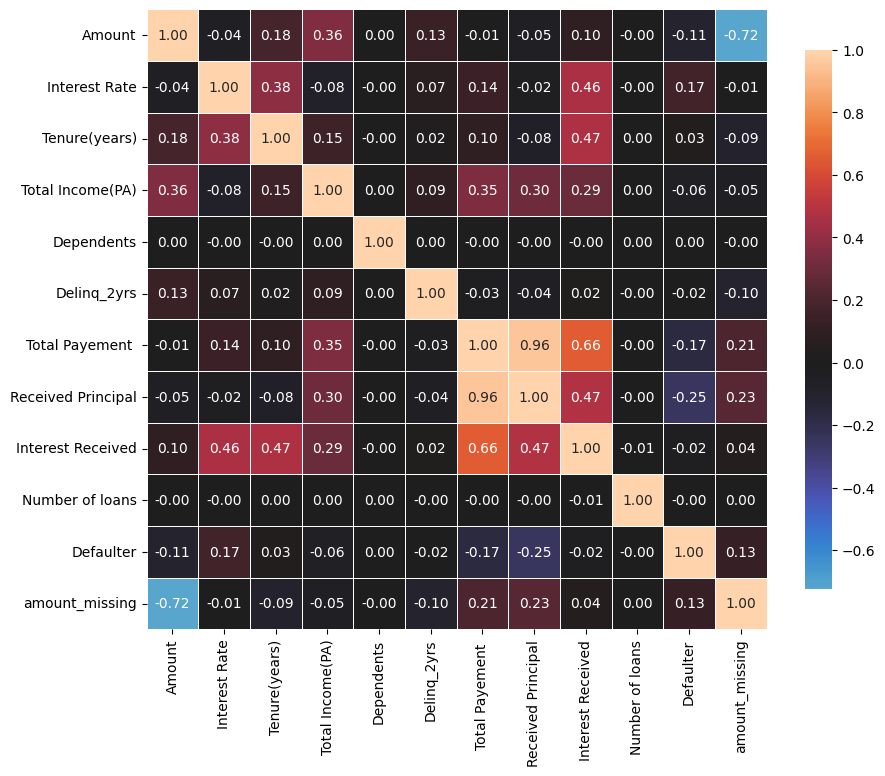

In [28]:
# Multicollinarity is the occurrence of high intercorrelations among two or more independent variables in a multiple regression mode

correlation_heatmap(df)

**Observation from the heatmap**

No two variables have high correlation with each other, so there is no issue of multicollinearity. It's safe to use all variables in machine learning model building.


**Spearman Correlation Coefficient**

Spearman works best if there are nonlinear relationships between different variables.

****

**We can confirm non-linear relationship b/w features by looking at pair-wise scatter plots below**

There are non-linear relationships b/w features, so our decision of going with spearman was CORRECT.

####**Scatter Plots to visualize correlations between x variables**

The following code generates a scatter plot matrix, also known as a pair plot, of all numeric features in the input DataFrame using the seaborn library.

The diagonal of the plot matrix shows a histogram of each variable's distribution. This allows for visual inspection of the pairwise relationships between variables, which can be useful for identifying patterns, trends, correlations, or potential outliers in the data.

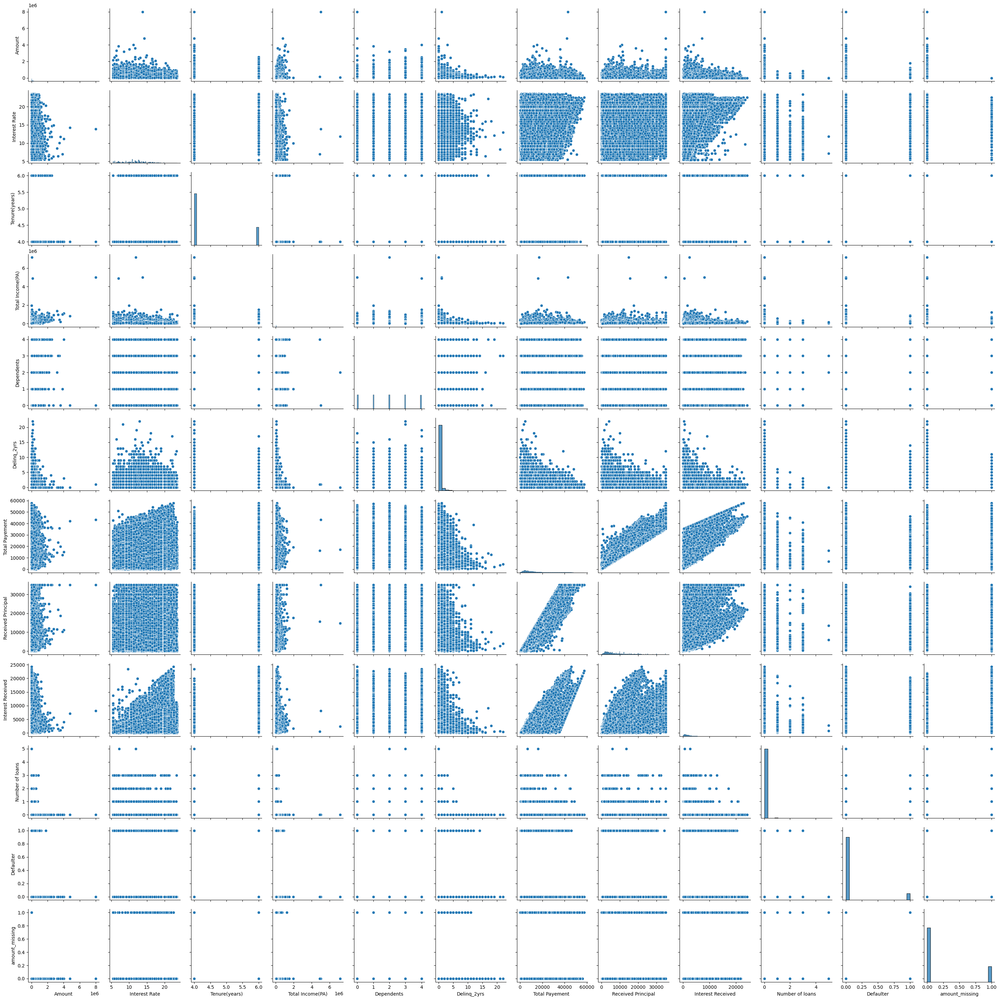

In [29]:
# Let's plot all interaction scatter plots using seaborn

# Call the function to plot pairwise scatter plots
plot_pairwise_scatter(df)



**Analysis**

****

- Scatterplots can help us confirm multicollinearity between two variables. We  can look at the scatterplot to check if there is any pattern or correlation between two variables.**

- Multicollinearity makes explainability less trustworthy as change in one variablte will not only impact the target variable but also impact other X variables. Means how much does a variable impact target variable would be hard



### **Skewness**

#### **Understand Skewness**

In [30]:
# To identify anomalies in each column, it is essential to examine the distributions of the variables in the dataset.

# Call the function to plot histograms
Feature_Distributions_Histogram(df)

**Concept of skewness:**

Imagine a seesaw in a playground. If the seesaw is perfectly balanced, it means both ends are at the same height and there is no tilt. Similarly, a symmetric distribution has equal amounts of data on both sides of the central point, resulting in a balance.

However, if the seesaw is tilted to one side, it indicates an imbalance. Similarly, if a distribution is skewed, it means there is more data concentrated on one side compared to the other. This imbalance causes the distribution to have a "tail" that stretches towards the side with fewer data points.

Skewness helps us understand the direction and degree of this imbalance. If the tail stretches to the right side, we call it positive skewness, indicating a longer right tail. Conversely, if the tail stretches to the left side, we call it negative skewness, indicating a longer left tail.

**Positive skewness:**

Imagine a line plot or histogram representing the heights of students in a class. In a class with right skewness, most students will have heights clustered towards the shorter side, and there will be a few students with taller heights. The right tail of the distribution will be longer, indicating the presence of outliers or extreme values on the taller side.

**Negative Skewness:**
Consider a line plot or histogram representing the time spent studying for an exam. In a situation with left skewness, most students might have relatively high study times, and there will be a few students with very low study times. The left tail of the distribution will be longer, indicating the presence of outliers or extreme values on the lower side.

**Analysis after Distribution:**

1. Amount: The distribution of the 'Amount' variable is right-skewed, indicating that a majority of loan amounts are lower, while a few instances have higher values.

2. Employment Type: The distribution of the 'Employment Type' variable shows an imbalance, suggesting that certain employment types may be overrepresented in the dataset compared to others.

3. Work Experience: The 'Work Experience' variable also exhibits imbalanced data, implying that certain levels of work experience may be more prevalent than others.

4. Pincode: The 'Pincode' variable contains a large number of categories, which may pose challenges for analysis. Considering converting it into latitude and longitude coordinates could offer a more manageable representation.

5. Delinq_2years: The distribution of the 'Delinq_2years' variable is right-skewed, indicating that most individuals have a low number of delinquencies, while a few have a higher count.

6. Payment: The 'Payment' variable displays a right-skewed distribution, suggesting that the majority of payment amounts are lower, with a few instances of higher payments.
7. Received Principal: The distribution of the 'Received Principal' variable is right-skewed, indicating that most individuals have received a lower principal amount, while a few have received a higher amount.

8. Interest Received: The 'Interest Received' variable exhibits a right-skewed distribution, suggesting that the majority of individuals have received a lower interest amount, while a few have received a higher interest payment.

**Outcome**

The resulting histograms will show the distribution of values in each column and can help identify potential outliers or anomalies in the data. For example, if a column has a very skewed distribution or contains a large number of extreme values, this may indicate that the data is not representative or that there are errors or issues with the data collection process.

Note that generating histograms for a large number of columns can be computationally intensive and may take some time to run, especially for large datasets.

#### **Fixing Skewness in the Data**

**Skewness**

- Skewness is a statistical measure that describes the asymmetry or lack of symmetry in a distribution. It provides insights into the shape of the distribution and the relative positioning of the mean, median, and mode.
- A positive skewness value indicates a right-skewed distribution, where the tail is elongated towards the right. A negative skewness value indicates a left-skewed distribution, where the tail is elongated towards the left. A skewness value of 0 indicates a symmetric distribution.
- By quantifying skewness, we can gain a numerical understanding of the distribution's asymmetry and further analyze its implications in data analysis and modeling


**How to quantify skewness?**

* skewness = 3 * (mean - median) / standard deviation.

****
**Question to consider**

* Should we remove outliers/extreme values first and then fix skewness or the otherway around?
****
**Decision**
* To address the presence of outliers in skewed data, we'll first correct the skewness.
* One approach to mitigating the impact of outliers is by utilizing the z-score. The z-score measures how many standard deviations an individual data point is away from the mean. By setting a threshold, such as 3 standard deviations, data points that exceed this threshold can be considered as outliers and subsequently removed from the dataset.


**Let's print skewness in each feature and use log transformation to fix skewness.**

**Note**

It is important to note that there are numerous features in the dataset with a value of 0. To address this issue and normalize the data, we can apply a log transformation specifically to the non-zero values. By taking the logarithm of these values, we can achieve a more symmetric distribution and reduce the impact of extreme values. This transformation can be particularly useful when working with skewed data or variables that exhibit a wide range of values.

Let's only transform features if skewness is in the following range
* **Skewness < -3 OR Skewness > 3**


In [31]:
# Add all the features to check and fix skewness in features_log array
# features_log= ['Amount','Interest Rate','Tenure(years)','Dependents','Total Payement ','Received Principal','Interest Received']

# df= fix_skewness(df, features_log)


### **One Hot Encoding of Categorical Features and Ordinal Encoding of Ordinal Features**




**Categorical and Ordinal Variables**

Categorical variables refer to variables that represent discrete categories or labels, such as gender (male/female), marital status (single/married/divorced), or product types (A/B/C). These variables do not have a specific numerical order or hierarchy.

On the other hand, ordinal variables also represent discrete categories, but they have an inherent order or ranking associated with them. Examples of ordinal variables include education level (elementary/middle/high school/college), employment status (unemployed/part-time/full-time), or customer satisfaction rating (low/medium/high).

#### **Categorical Hot-Encoding**

In [32]:
import pandas as pd

# Add all categorical features for categorical one-hot encoding in categorical_features array
data = df
categorical_features= ["Gender", "Married", "Home", "Social Profile", "Loan Category", "Employmet type","Is_verified", ]

# Perform one-hot encoding using pandas get_dummies() function
encoded_data = pd.get_dummies(data, columns=categorical_features)



#### **Ordinal Encoding**

In [33]:
# Define the ordinal categorical features array
ordinal_features = ["Tier of Employment", "Work Experience"]

# Define the pandas DataFrame for encoding
data = encoded_data

# Create a custom mapping of categories to numerical labels
tier_employment_order= list(encoded_data["Tier of Employment"].unique())
tier_employment_order.sort()

work_experience_order= [ 0, '<1', '1-2', '2-3', '3-5', '5-10','10+']

custom_mapping = [tier_employment_order, work_experience_order]

# Call the function to perform ordinal encoding
data = perform_ordinal_encoding(data, ordinal_features, custom_mapping)

In [34]:
data

,Amount,Interest Rate,Tenure(years),Tier of Employment,Work Experience,Total Income(PA),Dependents,Delinq_2yrs,Total Payement,Received Principal,...,Loan Category_Home,Loan Category_Medical,Loan Category_Other,Employmet type_Salaried,Employmet type_Self - Employeed,Employmet type_missing,Is_verified_Not Verified,Is_verified_Source Verified,Is_verified_Verified,Is_verified_missing
0,55884.0,11.84,6,1.0,2.0,125000.0,4,0,1824.150000,971.46,...,0,0,0,1,0,0,0,0,0,1
1,55511.0,16.94,4,3.0,6.0,61000.0,1,0,22912.532998,18000.00,...,0,0,0,0,1,0,0,1,0,0
2,12289.0,11.84,6,7.0,5.0,100000.0,3,0,7800.440000,4489.76,...,0,0,0,0,0,1,0,0,0,1
3,29324.0,14.71,4,7.0,3.0,30000.0,1,0,6672.050000,5212.29,...,0,0,0,0,0,1,0,0,0,1
4,30252.0,14.71,4,7.0,6.0,65000.0,3,0,11793.001345,10000.00,...,0,0,0,0,0,1,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
143722,287564.0,12.06,6,7.0,0.0,100000.0,2,1,12842.400000,7193.83,...,0,0,0,0,0,1,0,1,0,0
143723,49612.0,14.10,4,7.0,0.0,27000.0,3,0,839.200000,581.67,...,0,0,1,0,0,1,0,1,0,0
143724,13632.0,18.96,6,7.0,0.0,53000.0,2,0,6085.800000,2434.49,...,0,0,0,0,0,1,0,0,0,1
143725,186923.0,8.28,4,7.0,0.0,75400.0,0,0,4080.640000,3286.82,...,1,0,0,0,0,1,0,1,0,0


### **Fix data imbalance in the target variable**

**Oversampling**

 Increase the number of instances in the minority class (defaulters) by duplicating existing examples or generating synthetic examples to achieve a balanced dataset.

In [35]:
# Specify the name of the target variable column
target_column="Defaulter"

X, y= fix_imbalance_using_oversamping(data, target_column)


**SMOTE**

SMOTE (Synthetic Minority Over-sampling Technique) is a popular technique used in machine learning and data mining to address the issue of imbalanced datasets. Imbalanced datasets are characterized by a significant difference in the number of instances between the classes, where one class (the minority class) has a much smaller representation than the other class(es) (the majority class(es)).

SMOTE works by generating synthetic samples for the minority class to balance the class distribution. It does this by creating synthetic examples along the line segments connecting minority class instances. Here's a high-level overview of how SMOTE works:

For each instance in the minority class, SMOTE selects one or more of its k nearest neighbors from the same class. The value of k is a user-defined parameter.
Synthetic samples are created by randomly selecting one or more of the nearest neighbors and using them to form new samples. This is done by interpolating the feature values between the selected instance and its neighbor(s). For example, if there are two nearest neighbors, SMOTE can create a synthetic sample by taking a weighted average of the feature values of the two neighbors.
The synthetic samples are added to the dataset, effectively increasing the representation of the minority class. This process is repeated until the desired balance between the classes is achieved.
SMOTE helps to overcome the problem of imbalanced datasets by increasing the diversity of the minority class and reducing the bias towards the majority class during training. This can improve the performance of machine learning models by ensuring that the model is exposed to a more balanced representation of the data.


In [36]:
# import pandas as pd
# from imblearn.over_sampling import SMOTE

# # Assuming you have your pandas DataFrame df with features and target variable

# # Separate the features (X) and target variable (y) from the DataFrame
# X = data.drop('Defaulter', axis=1)
# y = data['Defaulter']

# # Initialize the SMOTE oversampling algorithm
# smote = SMOTE(random_state=42)

# # Convert X and y to NumPy arrays
# X_array = X.values
# y_array = y.values

# # Perform oversampling on the data
# X_resampled, y_resampled = smote.fit_resample(X_array, y_array)

# # Convert the resampled arrays back to a pandas DataFrame
# X_resampled_df = pd.DataFrame(X_resampled, columns=X.columns)
# y_resampled_df = pd.DataFrame(y_resampled, columns=['target'])

# # Print the class distribution before and after oversampling
# print("Class distribution before oversampling:")
# print(y.value_counts())

# print("Class distribution after oversampling:")
# print(y_resampled_df['target'].value_counts())

# X= X_resampled_df
# y= y_resampled_df


## **Split Data in training, validation, and testing datasets**

In [37]:
from sklearn.model_selection import train_test_split

#The test_size parameter is set to 0.2, indicating that 20% of the data will be allocated to the testing set, while the remaining 80% will be used for training.
#The random_state parameter is set to 42 to ensure reproducibility of the split, meaning that the same random split will be obtained each time the code is executed.
train_x, test_x, train_y, test_y = train_test_split(X, y, test_size=0.2, random_state=42)

# val_x, test_x, val_y, test_y = train_test_split(test_x, test_xy, test_size=0.5, random_state=42)


## **Model Training: Xgboost**

### **Import packages**

In [38]:
import numpy as np
import xgboost as xgb
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
import time
from hyperopt import fmin, tpe, hp, STATUS_OK
from hyperopt.pyll import scope
import neptune
from neptune.integrations.xgboost import NeptuneCallback


import pickle
from sklearn.metrics import classification_report, confusion_matrix

### **Configure Neptune**

Format:

# Create a Neptune run object
run = neptune.init_run(
    project="your-workspace-name/your-project-name",  
    api_token="YourNeptuneApiToken",  
    tags=["quickstart", "script"],  # optional
)

In [ ]:
# Configure Neptune
run = neptune.init_run(
    project="your-workspace/your-project-name",
    api_token="enter-api-key",
)  # your credentials

# Creating a NeptuneCallback object to integrate Neptune with XGBoost.
neptune_callback = NeptuneCallback(run=run, log_tree=[0, 1, 2, 3])


### **Model training with hyperopt**

**XGBoost hyperparameters**
***
- **Boosting hyperparameters:** Control the gradient descent process in boosting.

- **Tree hyperparameters:** Influence the construction of decision trees.

- **Stochastic hyperparameters:** Determine the subsampling of training data during model building.

- **Regularization hyperparameters:** Regulate model complexity to prevent overfitting.
***

In [ ]:
# Define search space for hyperparameter tuning of XGBoost model.
search_space = {
    'learning_rate': hp.loguniform('learning_rate', -7, 0),
    'max_depth': scope.int(hp.uniform('max_depth', 1, 100)),
    'min_child_weight': hp.loguniform('min_child_weight', -2, 3),
    'subsample': hp.uniform('subsample', 0.5, 1),
    'colsample_bytree': hp.uniform('colsample_bytree', 0.5, 1),
    'gamma': hp.loguniform('gamma', -10, 10),
    'alpha': hp.loguniform('alpha', -10, 10),
    'lambda': hp.loguniform('lambda', -10, 10),
    'objective': 'binary:logistic',
    'eval_metric': 'error',
    'seed': 123,
}
train_x=train_x
train_y=train_y
test_x=test_x
test_y=test_y


# Finding the best hyperparameters using Hyperopt's fmin function.
best_params = fmin(
    fn=lambda params: train_model_xgboost(params, neptune_callback, train_x, train_y, test_x, test_y),
    space=search_space,
    algo=tpe.suggest,
    max_evals=15,
    rstate=np.random.default_rng(123)
)
run.stop()

# Let's print the params
print(best_params)

# Rest of the code remains the same


### **Best fit xgboost model**


In [ ]:
# Access the best hyperparameters
best_hyperparams = {k: best_params[k] for k in best_params}

# Train the final XGBoost model with the best hyperparameters
final_model = xgb.XGBClassifier(
    max_depth=int(best_hyperparams['max_depth']),
    learning_rate=best_hyperparams['learning_rate'],
    gamma=best_hyperparams['gamma'],
    subsample=best_hyperparams['subsample'],
    colsample_bytree=best_hyperparams['colsample_bytree'],
    random_state=42,
    tree_method='hist',enable_categorical= True,  # Use GPU for faster training (if available)
)

final_model.fit(train_x, train_y)  # Train the final model on the entire dataset

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.9941458252246209, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              gamma=4995.254471659089, gpu_id=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.09100767117912448, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=29, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              n_estimators=100, n_jobs=None, num_parallel_tree=None,
              predictor=None, random_state=42, ...)

###**Model validation**

In [ ]:
# Assuming `test_x` contains your test feature data
# Assuming `test_y` contains your test target labels
from sklearn.metrics import classification_report, confusion_matrix

# Make predictions on the test data
y_pred = final_model.predict(test_x)

# Print classification metrics
print("Classification Report:")
print(classification_report(test_y, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(test_y, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.83      0.79     25937
           1       0.81      0.75      0.78     26165

    accuracy                           0.79     52102
   macro avg       0.79      0.79      0.79     52102
weighted avg       0.79      0.79      0.79     52102

Confusion Matrix:
[[21453  4484]
 [ 6630 19535]]


###**Save best fit model**

In [ ]:
# Load the model from the file
filename = 'drive/MyDrive/projectpro/1_explainable_ai/xgboost_model.pkl'
final_model = pickle.load(open(filename, 'rb'))


# Read the testing data to a file
filename = 'drive/MyDrive/projectpro/1_explainable_ai/testing_data_iteration2.pkl'
with open(filename, 'rb') as file:
    test_x, test_y = pickle.load(file)


# Read the training data to a file
filename2 = 'drive/MyDrive/projectpro/1_explainable_ai/training_data_iteration2.pkl'
with open(filename2, 'rb') as file:
    train_x, train_y= pickle.load(file)


## **Model Training: RandomForest**

###**Random forest Grid Search**

In [ ]:
# Define your parameter grid
param_grid = {
        'n_estimators': [100, 200, 300],
        'max_depth': [None, 5, 10],
        'min_samples_split': [2, 5, 10]
    }


best_parameters=random_forest_classifier_grid_search(param_grid, train_x, train_y)

best_parameters

{'max_depth': None, 'min_samples_split': 2, 'n_estimators': 300}

**Best Parameters:**
- **'max_depth'**: None
- **'min_samples_split'**: 2
- **'n_estimators'**: 300

###**Model Validation Random Forest**

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

# Access the best hyperparameters
best_hyperparams = {k: best_parameters[k] for k in best_parameters}

# Train the randomforest model with the best hyperparameters
final_model1 = RandomForestClassifier(
    max_depth=best_hyperparams['max_depth'],
    min_samples_split=best_hyperparams['min_samples_split'],
    n_estimators=best_hyperparams['n_estimators'],
     # Use GPU for faster training (if available)
)

final_model1.fit(train_x, train_y)  # Train the final model on the entire dataset


# Assuming `test_x` contains your test feature data
# Assuming `test_y` contains your test target labels


# Make predictions on the test data
y_pred = final_model1.predict(test_x)

# Print classification metrics
print("Classification Report:")
print(classification_report(test_y, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(test_y, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      1.00     25937
           1       0.99      1.00      1.00     26165

    accuracy                           1.00     52102
   macro avg       1.00      1.00      1.00     52102
weighted avg       1.00      1.00      1.00     52102

Confusion Matrix:
[[25773   164]
 [    0 26165]]


###**Save Random Forest**

In [ ]:
import pickle


filename = 'Output/RandomForest_model.pkl'

# # save the model into the file
pickle.dump(final_model1, open(filename, 'wb'))


# Load the model using the lines below
# filename = 'drive/MyDrive/projectpro/1_explainable_ai/RandomForest_model.pkl'
# final_model1 = pickle.load(open(filename, 'rb'))
